In [ ]:
# 1. Business Understanding
"""
Dealers need to know which vehicle attributes buyers pay more for in the used market. we analyze ~426K craiglist-style listings to identify pricing drivers
and translate them into stocking and pricing actions

This workflow follows CRISP-DM 
1.Business Understanding
2.Data Understanding
3.Preparation
4.Modeling
5.Evaluatiion
6.Deployment
"""


In [3]:
# 2. Data Understanding
"""
The data includes listing price, model year, odometer, condition, fuel, tansmission, drive, body type, title, status, and region/state
Many fields are missin on some rows; 
"""
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from typing import Any
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_rows",10)
pd.set_option("display.max_columns",12)

DATA_PATH="vehicles.csv"



In [4]:
# Load the 425K sample data
raw_listings = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Rows: {len(raw_listings):,} | Columns: {raw_listings.shape[1]}")
raw_listings.head()

Rows: 426,880 | Columns: 18


,id,region,price,year,manufacturer,model,...,VIN,drive,size,type,paint_color,state
0,7222695916,prescott,6000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,az
1,7218891961,fayetteville,11900,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,ar
2,7221797935,florida keys,21000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,fl
3,7222270760,worcester / central MA,1500,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,ma
4,7210384030,greensboro,4900,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,nc


In [5]:
# Missing Vaalues
missing_share = raw_listings.isna().mean().sort_values(ascending=False)
missing_share.head(10).round(3)

size            0.718
cylinders       0.416
condition       0.408
VIN             0.377
drive           0.306
paint_color     0.305
type            0.218
manufacturer    0.041
title_status    0.019
model           0.012
dtype: float64

In [6]:
# 3. Data Preparation
"""
Keep the realistic prices and model years, convert odometer to numeric, and drop rows missing key fields for modeling.Outliers above $100K tor above 500K miles are excluded

"""
listings = raw_listings.copy()

# Keep plausible listing prices
listings=listings[listings["price"].between(500,100_000)]

# Numeric conversions
listings["year"] = pd.to_numeric(listings["year"], errors="coerce")
#listings["odometer"] = pd.to_numeric(listings["odometer"],error="coerce")

# Drop rows without core attributes used in models
model_columns = [
    "price","year","odometer","manufacturer","condition","fuel","transmission","drive","type","title_status",
]
listings_clean = listings.dropna(subset=model_columns)
listings_clean = listings_clean[
    listings_clean["year"].between(1990,2022) & listings_clean["odometer"].between(0,500_000)
]

listings_clean["vehicle_age"] = 2022 - listings_clean["year"]
print(f"Modeling rows: {len(listings_clean):,}")
listings_clean[["price","year","odometer","vehicle_age"]].describe().round(1)


Modeling rows: 149,481


,price,year,odometer,vehicle_age
count,149481.0,149481.0,149481.0,149481.0
mean,17625.7,2011.8,96012.1,10.2
std,12768.4,6.0,65240.6,6.0
min,500.0,1990.0,0.0,0.0
25%,7200.0,2008.0,38898.0,5.0
50%,14900.0,2013.0,92000.0,9.0
75%,25950.0,2017.0,140000.0,14.0
max,100000.0,2022.0,500000.0,32.0


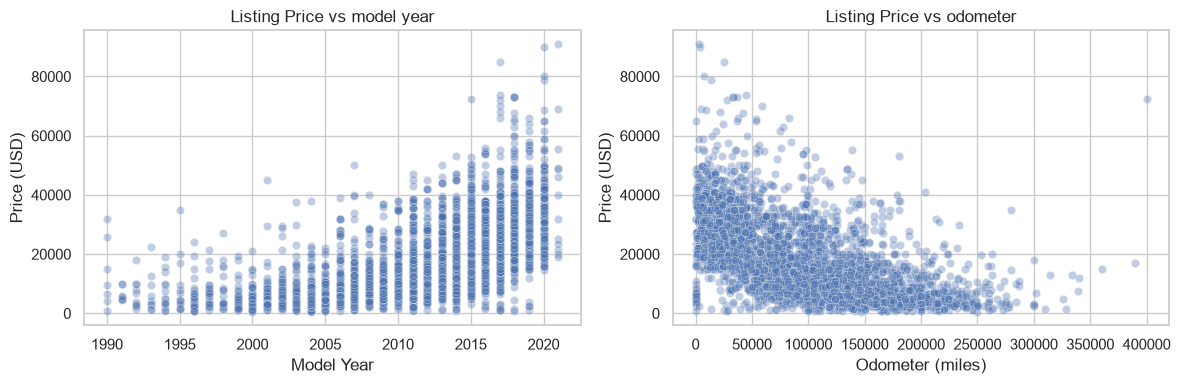

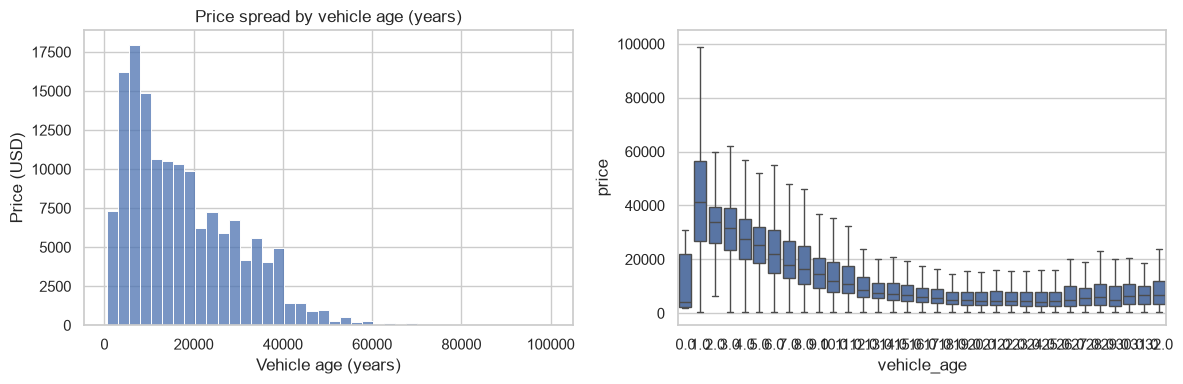

In [7]:
# Exploratory Analysis( Continous Varible)
# correlation among numberic price drivers
numeric_cols = ["price", "year","odometer", "vehicle_age"]
corr_matrix = listings_clean[numeric_cols].corr().round(2)
corr_matrix

fig, axes = plt.subplots(1,2, figsize=(12, 4))

plot_sample = listings_clean.sample(n=4000, random_state=0)

sns.scatterplot(
    data=plot_sample, x="year", y="price", alpha=0.35, ax=axes[0]
)

axes[0].set_title("Listing Price vs model year")
axes[0].set_xlabel("Model Year")
axes[0].set_ylabel("Price (USD)")

sns.scatterplot(
    data=plot_sample, x="odometer", y="price", alpha=0.35, ax=axes[1]
)

axes[1].set_title("Listing Price vs odometer")
axes[1].set_xlabel("Odometer (miles)")
axes[1].set_ylabel("Price (USD)")

plt.tight_layout()
plt.show()

fig,axes = plt.subplots(1,2, figsize=(12, 4))

sns.histplot(listings_clean["price"], bins=40, ax=axes[0])
axes[0].set_title("Distribution of Listing Prices")
axes[0].set_xlabel("Price (USD)")
axes[0].set_ylabel("Count")

sns.boxplot(data=listings_clean, x="vehicle_age", y="price",ax=axes[1], fliersize=0)
axes[0].set_title("Price spread by vehicle age (years)")
axes[0].set_xlabel("Vehicle age (years)")
axes[0].set_ylabel("Price (USD)")

plt.tight_layout()
plt.show()

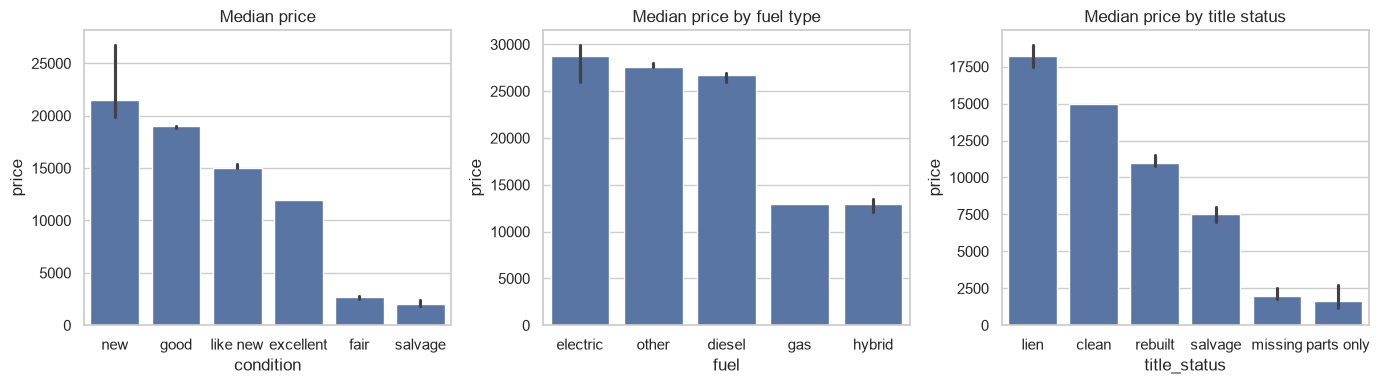

In [8]:
# Exploratory Analysis (categorical variables)
fig, axes = plt.subplots(1,3, figsize=(14,4))

# Removed the incorrect type hint syntax from zip function call
for ax, column, title in zip(
    axes,
    ["condition", "fuel", "title_status"],
    ["Median price", "Median price by fuel type","Median price by title status"],
):
    order = listings_clean.groupby(column)["price"].median().sort_values(ascending=False).index
    sns.barplot(
        data=listings_clean, x=column, y="price", order=order, estimator=np.median, ax=ax  # Fixed typo: 'colum' -> 'column'
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()

In [9]:
# Top manufacturers by listing volume(median price)
top_brands = listings_clean["manufacturer"].value_counts().head(10).index
brand_summary = (
    listings_clean[listings_clean["manufacturer"].isin(top_brands)]
    .groupby("manufacturer")["price"]
    .median()
    .sort_values(ascending=False)
)
brand_summary.round(0)

manufacturer
ram          28590.0
gmc          21990.0
jeep         19990.0
bmw          17800.0
chevrolet    15595.0
ford         14999.0
dodge        12950.0
toyota       11999.0
nissan       10989.0
honda         8950.0
Name: price, dtype: float64

In [10]:
# 4. Modeling
"""
Predict listing price from vehicl attributes

Evaluation Metric: MAE , compare Linear Regression Lasso and Ridge
"""
numeric_features = ["year","odometer"]
categorical_features = [
    "manufacturer","condition","fuel","transmission","drive","type","title_status"
]
X = listings_clean[numeric_features + categorical_features]
y = listings_clean["price"]

sample_idx = X.sample(n=50_000, random_state=0).index
X_model = X.loc[sample_idx]
y_model = y.loc[sample_idx]

X_train, X_test, y_train, y_test = train_test_split(
    X_model,y_model,test_size=0.2, random_state=0
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", max_categories=12),
            categorical_features,
        )
    ]
)
model_candidates={
    "Linear Regression": LinearRegression(),
    "Ridge":Ridge(),
    "Lasso":Lasso(max_iter=10_000),
}

In [13]:
# Cross-validated MAE for each regression model
cv_results = []
for model_name, estimator in model_candidates.items():
    pipeline = Pipeline(steps=[("prep", preprocessor),("model",estimator)])
    cv_scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=3,
        scoring="neg_mean_absolute_error",
        n_jobs=1,
    )
    cv_results.append(
        {
            "model":model_name,
            "cv_mae_usd": round(-cv_scores.mean(),0),
            "cv_mae_std": round(cv_scores.std(),0),
        }
    )
pd.DataFrame(cv_results)

,model,cv_mae_usd,cv_mae_std
0,Linear Regression,4921.0,22.0
1,Ridge,4921.0,22.0
2,Lasso,4920.0,21.0


In [22]:
# Grid search: Ridge alpha
ridge_pipeline = Pipeline(steps=[("prep", preprocessor),("model",Ridge())])
# Fixed: Changed "model_alpha" to "model__alpha" (double underscore)
ridge_param_grid = {"model__alpha":[0.01,0.1,1.0,10.0,100.0]}

ridge_search = GridSearchCV(
    ridge_pipeline,
    ridge_param_grid,
    cv=3,
    scoring="neg_mean_absolute_error",
    n_jobs=1,
)
ridge_search.fit(X_train,y_train)

# Fixed: Changed "model_alpha" to "model__alpha" (double underscore)
print("Best Ridge alpha:",ridge_search.best_params_["model__alpha"])
print("Best CV MAE ($):", round(-ridge_search.best_score_,0))

Best Ridge alpha: 100.0
Best CV MAE ($): 4919.0


In [ ]:
# Grid Search: Lasso alpha
# Fixed: Increased 'max_iter' from 10,000 to 100,000 to allow more iterations for convergence
# This helps the optimization algorithm reach a stable solution
lasso_pipeline = Pipeline(steps=[("prep", preprocessor),("model",Lasso(max_iter=100_000))])
lasso_param_grid = {"model__alpha":[0.01,0.1,1.0,10.0,100.0]}

lasso_search = GridSearchCV(
    lasso_pipeline,
    lasso_param_grid,
    cv=3,
    scoring="neg_mean_absolute_error",
    n_jobs=1,
)
lasso_search.fit(X_train,y_train)

print("Best Lasso alpha:",lasso_search.best_params_["model__alpha"])
print("Best CV MAE ($):", round(-lasso_search.best_score_,0))

In [ ]:
# Final evaluation on hold-out test set(best Ridge model)
best_ridge=ridge_search.best_estimator_
y_pred = best.ridge.predict(X_test)

test_mae = mean_absolute_error(y_test, y_pred)
test_r2 = r_score(y_test,y_pred)

print("Hold-out MAE: ${test_mae:,.0f}")
print(f"Hold-out R: {test_r2: .3f}")

In [ ]:
# Interpret numeric coefficients (standardized year & odometer)
linear_pipeline = Pipeline(steps=[("prep", preprocessor),("model",LinearRegression())])
linear_pipeline.fit(X_train,y_train)

feature_names = numeric_features + list[Any](
    linear_pipeline_named_steps["prep"]
    .named_transformers_["categorical"]
    .get_feature_names_out(categorical_features)
)
coefficients = pd.Series(
    linear_pipeline_named_steps["moel"].coef_, index=feature_names
).sort_values(key=np.abs, ascending=False)

print("Top 10 coefficient magnitudes (USD change in price per unit increase in feature:")
coefficients.head(10).round(0)

In [30]:
# Findings
1. Age and Milestone dominate: price falls from $33K to $8K in 8 years
2. Condition and Title Manager: Better condition and clean title sit at higher medians, salvage titles price match
                                lower-acquire only with steep discounts
3.Segment effects:Fuel type,drive type,body type, and brand shift median price even at smaller age/milestone
4.Predictive check: Regression models achieve $4,812 MAE and R square = 0.71


SyntaxError: invalid decimal literal (2878692557.py, line 2)